# My Python and C++ runtime/accuracy comparison
I benchmark fixed-lambda B1 with matched settings. I display two panels per sweep: measured runtime and observed relative volume error. I vary lambda at fixed n=9 and n at fixed lambda=1.5. My repeat ranges are observed variation, not confidence intervals.

The saved CSV is a development-environment pilot, not a measurement from my Mac. I can rerun it on my machine. Compilation, prompts, plotting, imports, and process startup are outside the timed calculation. I do not use this comparison to assess the theorem; I study the practical cost and errors of my numerical implementations.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "cpp/mixed_volume_experiment.cpp").exists():
    raise RuntimeError("Open this notebook from the repository root or notebooks directory.")

import json, subprocess
sys.path.insert(0,str(ROOT/"benchmarks"))
from plot_comparison import load_rows, plot_sweep
import matplotlib.pyplot as plt


## My optional benchmark controls
I set RUN_BENCHMARK to True only when I want to regenerate the measurements. All parameters are editable. Larger budgets take longer. I use three seeds to avoid selecting only the lowest-error run.

In [2]:
RUN_BENCHMARK = False
FIXED_N = 9
LAMBDA_VALUES = [0.5,1.5,3.0]
DIMENSIONS = [7,9,11]
FIXED_LAMBDA = 1.5
SAMPLES = 2000       # Recorded observations per volume phase
BURN_IN = 2000       # Initial discarded walk moves per phase
SPACING = 5          # Walk moves before each recorded observation
REPEATS = 3          # Distinct seeded runs per configuration
TOLERANCE = 1e-9     # Chord endpoint stopping width
COMPILER = "clang++"
if RUN_BENCHMARK:
    command=[sys.executable,str(ROOT/"benchmarks/run_comparison.py"),"--compiler",COMPILER,
             "--dimension",str(FIXED_N),"--lambda-fixed",str(FIXED_LAMBDA),
             "--samples",str(SAMPLES),"--burn-in",str(BURN_IN),"--spacing",str(SPACING),
             "--repeats",str(REPEATS),"--tolerance",str(TOLERANCE),
             "--lambdas",*map(str,LAMBDA_VALUES),"--dimensions",*map(str,DIMENSIONS)]
    subprocess.run(command,check=True)
else:
    print("I am displaying the saved measurements; I have not run the editable settings above.")


I am displaying the saved measurements; I have not run the editable settings above.


In [3]:
environment = json.loads((ROOT/"results/benchmark_environment.json").read_text())
print("Actual saved measurement environment:")
print(json.dumps(environment,indent=2))
rows = load_rows()
print("Recorded runs:",len(rows))
settings = environment['settings']


Actual saved measurement environment:
{
  "measured_at": "2026-10-10T06:45:17Z",
  "platform": "Linux-6.18.44-x86_64-with-glibc2.39",
  "machine": "x86_64",
  "python": "3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]",
  "numpy": "2.3.5",
  "compiler": "c++ (Ubuntu 13.3.0-6ubuntu2~24.04) 13.3.0\nCopyright (C) 2023 Free Software Foundation, Inc.\nThis is free software; see the source for copying conditions.  There is NO\nwarranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.\n\n",
  "compile_command": [
    "/usr/bin/c++",
    "-std=c++17",
    "-O2",
    "/workspace/scratch/43b50014267d/mixed-volume-repo/cpp/mixed_volume_experiment.cpp",
    "-o",
    "/workspace/scratch/43b50014267d/mixed-volume-repo/results/mixed_volume_benchmark"
  ],
  "settings": {
    "compiler": "c++",
    "dimension": 9,
    "lambdas": [
      0.5,
      1.5,
      3.0
    ],
    "dimensions": [
      7,
      9,
      11
    ],
    "lambda_fixed": 1.5,
    "samples": 2000,
    "burn

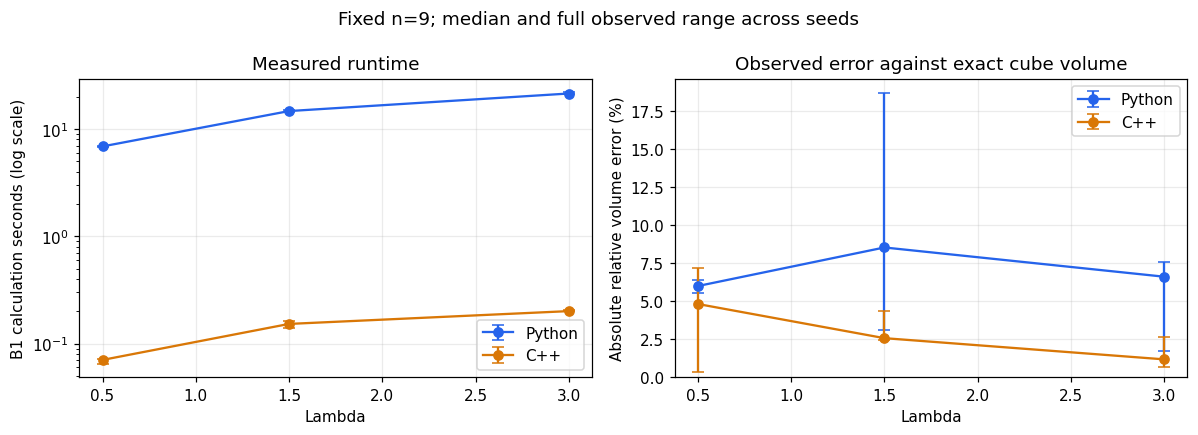

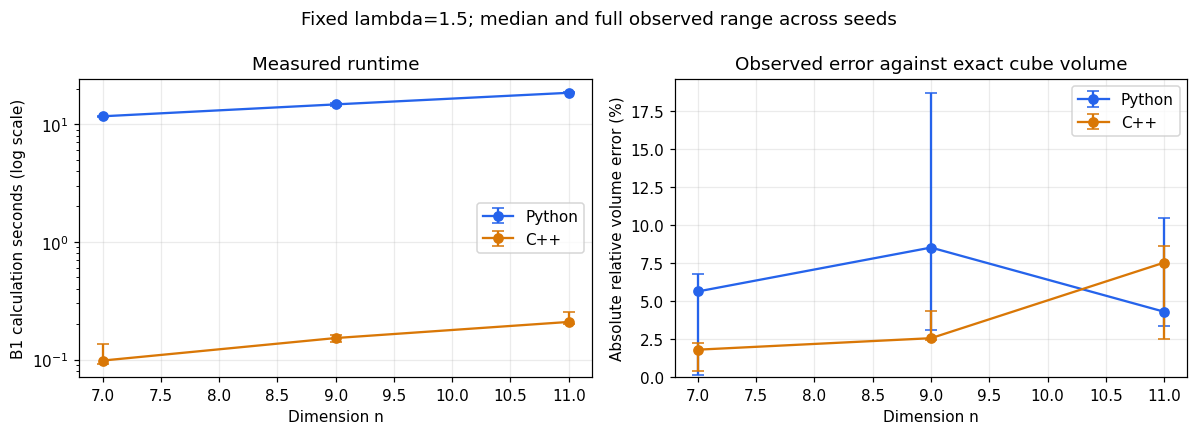

In [4]:
plot_sweep(rows,"lambda",settings['dimension'])
plt.show()
plot_sweep(rows,"dimension",settings['lambda_fixed'])
plt.show()


## What I conclude and what I leave open
I report runtime and error together. I do not assume that faster code gives more uniform points. Equal seeds across languages do not imply equal trajectories. I record phase counts because geometric changes alter the workload. I use separate fixed-lambda B1 tests to avoid confounding runtime with Algorithm 2's random search decisions.

This pilot does not certify mixing, oracle accuracy, or performance on general polytopes. My next comparisons increase budgets and inspect correlations and burn-in sensitivity. I save the notebook after rerunning so its embedded charts match the current CSV.